# Student Performance ETL Pipeline for Data Analysis

*Author: Chikondi Banda*

Analysis the factors affecting student performance in the Student performance factors dataset

Data source: https://www.kaggle.com/datasets/lainguyn123/student-performance-factors

Recommendations based on findings:

1.   Invest in learning disability support
2.   Advocate for internet access to home to aid with studying
3.   Encourage personal study
4.   Encourage students to attend all classes and pay attention during class




In [7]:
# Extract the data
import pandas as pd

df = pd.read_csv('StudentPerformanceFactors.csv')
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [8]:
# Check dataset size
df.shape

(6607, 20)

In [9]:
#Check for null values
df.isnull().sum()

,0
Hours_Studied,0
Attendance,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0


In [10]:
# Check data types
df.dtypes

,0
Hours_Studied,int64
Attendance,int64
Parental_Involvement,object
Access_to_Resources,object
Extracurricular_Activities,object
Sleep_Hours,int64
Previous_Scores,int64
Motivation_Level,object
Internet_Access,object
Tutoring_Sessions,int64


In [11]:
# Check for outliers or irregularities
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [12]:
# Clean the data

def clean_data(df):
  df.drop_duplicates()
  df.dropna()
  df = df[df.Exam_Score <= 100]
  return df


In [13]:
#Tranform the data
def transform_data(df):
  df['Performance'] = pd.cut(df['Exam_Score'],
                             bins=[0, 60, 80, 100],
                             labels=['Needs Improvement',
                                     'Good',
                                     'Exellent'])
  df['Attendance_Group'] = pd.cut(df['Attendance'],
                                  bins=[0, 70, 90, 100],
                                  labels=['Low',
                                          'Mid',
                                          'High'])
  return df

In [27]:
#Analysis
def analyze_data(df):
  summary = df.groupby('Attendance_Group').agg(
      avg_study=('Hours_Studied', 'mean'),
      avg_sleep=('Sleep_Hours', 'mean'),
      students=('Hours_Studied', 'count'),
      score=('Exam_Score', 'mean')
  )
  corr = df.corr(numeric_only=True)
  return summary, corr

In [15]:
# Load results
def load_results(df, summary):
  df.to_csv('transformed_data.csv')
  summary.to_csv('analysis_results.csv')

In [28]:
# Automate the pipeline
df = clean_data(df)
df = transform_data(df)
summary, corr = analyze_data(df)
load_results(df, summary)

/tmp/ipykernel_16066/3247129200.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = df.groupby('Attendance_Group').agg(


In [29]:
analysis = pd.read_csv('analysis_results.csv')
analysis.head()

,Attendance_Group,avg_study,avg_sleep,students,score
0,Low,19.978085,7.055363,1734,64.330450
1,Mid,20.013098,7.032592,3283,67.356077
2,High,19.889868,6.993707,1589,70.135935


** Further investigation into lower grades required

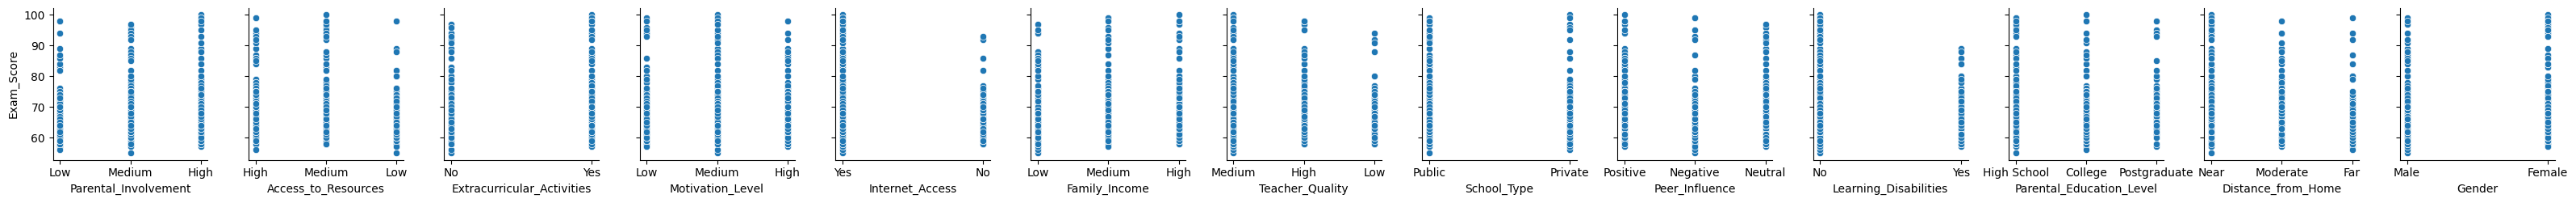

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

# Investigate relationships between categorical variables
sns.pairplot(data=df,
    y_vars=['Exam_Score'],
    x_vars=['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level',
            'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type',
            'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender'])
plt.show()

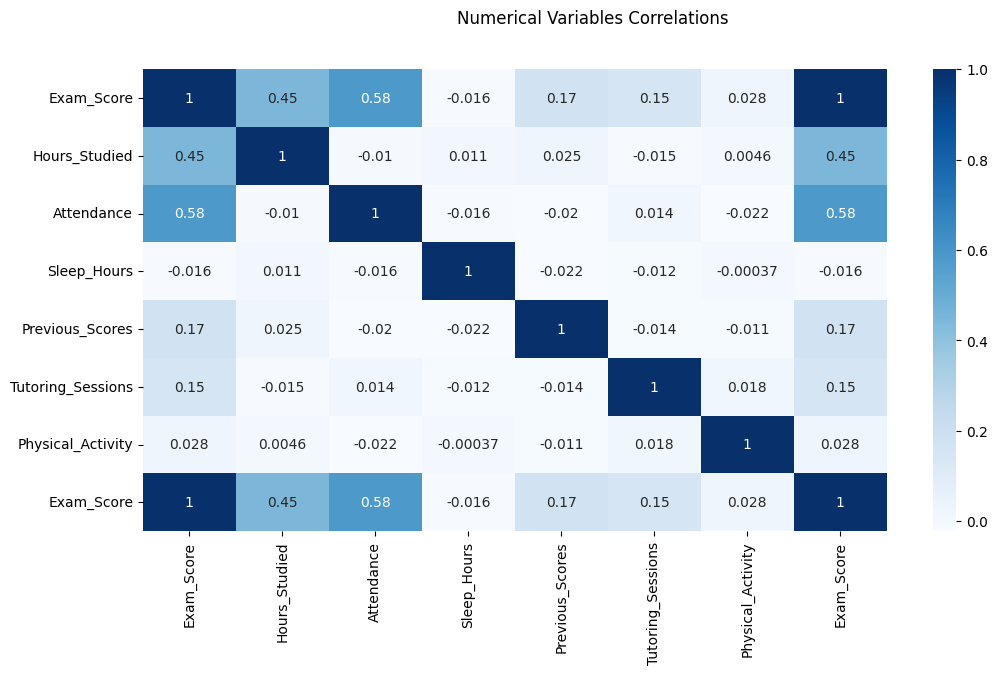

In [34]:
# Investigate relationships between numerical variables

num_vars = df[['Exam_Score',
               'Hours_Studied',
                'Attendance',
                'Sleep_Hours',
                'Previous_Scores',
                'Tutoring_Sessions',
                'Physical_Activity',
                'Exam_Score']]

corr = num_vars.corr()
fig, ax = plt.subplots(figsize=(12, 6))
fig.suptitle("Numerical Variables Correlations")
sns.heatmap(corr, cmap="Blues", xticklabels=corr.columns, yticklabels=corr.columns, annot=True)
plt.show()